# Linear Models in Machine Learning — Predicting Systolic Blood Pressure

In this practical session, you will get hands-on experience with **linear regression** by trying to predict  
**systolic blood pressure (`sysBP`)** using real data from the Framingham Heart Study.

---

## What you will learn
By the end of this notebook, you will:

1. Go through the main steps of solving a regression problem:
   - Load and explore a dataset  
   - Choose features and a target variable  
   - Build a simple baseline model  
   - Train a linear regression model  
   - Interpret the model’s coefficients and predictions  
   - Try out multiple regression

2. Discover and practice using the **R² metric** to evaluate how well a regression model performs.

3. Test your understanding with about **20 interactive Wooclap questions** linked to this session.

---

## The dataset
We will work with a public version of the **Framingham dataset (CSV)**.  
Our target is `sysBP` (systolic blood pressure).  
Predictors include demographic, lifestyle, laboratory, and clinical variables:

- **Numeric**: `age`, `totChol`, `diaBP`, `BMI`, `heartRate`, `glucose`  
- **Categorical**: `male`, `education`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp`, `diabetes`

---

## Why this notebook is useful
Think of this notebook as a **toolbox of recipes** that you can reuse in future projects.  
Here, you’ll practice how to:
- Visualize linear regression results  
- Automatically compare **R² values** across features  
- Build and interpret multiple regression models  
- Handle both categorical and continuous predictors in regression  

*Note:* The notebook does not contain the solutions to the Wooclap questions — those are for you to work out during the session.


## What is Systolic Blood Pressure?

Blood pressure is measured in **millimeters of mercury (mmHg)** and reported as two numbers:

- **Systolic blood pressure (sysBP):** the *upper number* — the pressure in the arteries **when the heart contracts** (pumping blood out).
- **Diastolic blood pressure (diaBP):** the *lower number* — the pressure in the arteries **when the heart relaxes** between beats.

Example:  
A reading of **120 / 80 mmHg** means:
- **120** mmHg = systolic (pressure during contraction)  
- **80** mmHg = diastolic (pressure during relaxation)

Typical interpretation of systolic blood pressure (adults):

| Category              | Systolic BP (mmHg) |
|-----------------------|---------------------|
| Normal                | < 120              |
| Elevated              | 120–129            |
| High (Hypertension 1) | 130–139            |
| High (Hypertension 2) | ≥ 140              |

In our dataset, **`sysBP` is the prediction target** — the continuous value we want to estimate from other patient variables.


## For your information

In spoken French, blood pressure values are traditionally **divided by 10**:

* **120 mmHg → “12”**
* **80 mmHg → “8”**

In France, a doctor will commonly say:

> **« Vous avez douze huit de tension. »**

meaning **120/80 mmHg** (*“you have twelve-eight blood pressure”*).

Although it is written **12/8**, the slash is usually **not pronounced** in everyday spoken French.

Thus:

* **12/8 = 120/80 mmHg**
* **14/9 = 140/90 mmHg** — a commonly used threshold for hypertension in a medical setting.

This is simply a convention used in spoken French. Blood pressure is still formally measured and reported in **mmHg (millimetres of mercury)**.


### The Framingham dataset

The **Framingham dataset** is derived from the **Framingham Heart Study**, a long-term cardiovascular study initiated in **1948 in Framingham, Massachusetts (USA)**.

The dataset contains demographic, behavioral, and clinical information, including **age, sex, smoking status, blood pressure, cholesterol, BMI, diabetes, and glucose levels**. The variable `TenYearCHD` indicates whether a participant developed **coronary heart disease (CHD) within 10 years**.

The `framingham.csv` version used here is a simplified dataset commonly used for teaching statistics and machine learning. It can be downloaded from **MIT OpenCourseWare – The Analytics Edge**:

https://ocw.mit.edu/courses/15-071-the-analytics-edge-spring-2017/resources/framingham/


In [2]:

%pip install pandas
# ======================================
# 2. Load the dataset
# ======================================

import pandas as pd

# Mount Google Drive if dataset is stored there
# from google.colab import drive
# drive.mount('/content/drive')

# Replace the path below with your dataset location
df = pd.read_csv("https://ocw.mit.edu/courses/15-071-the-analytics-edge-spring-2017/5d689a024551e672313f7fd7eb1bee8d_framingham.csv")

# Quick look at the dataset
print(df.shape)
display(df.head())
df.describe(include='all').T



Note: you may need to restart the kernel to use updated packages.
(4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


### [Checkpoint S1]  
 
**Q1:** How many patients in the database ? 

**Q2:** How many Columns in the database ?

**Q3:** what is the age average of the patients ? 


In [4]:
# code to check some answers:
#lines

print(len(df))
print(len(df.columns))
print(f"{sum(df["age"])/len(df):.1f}")




4240
16
49.6


### Exploring a pandas DataFrame

A pandas `DataFrame` provides **hundreds of methods and attributes**. You do not need to memorize them all!

In JupyterLab, type:

`df.`

and press **Tab** to explore the available methods and attributes.

#### A small pandas survival kit

| What do I want to do?  | pandas command             |
| ---------------------- | -------------------------- |
| Display the first rows | `df.head()`                |
| Display the last rows  | `df.tail()`                |
| Get the number of rows | `len(df)`                  |
| Get rows × columns     | `df.shape`                 |
| Get column names       | `df.columns`               |
| Check data types       | `df.dtypes`                |
| Get an overview        | `df.info()`                |
| Get summary statistics | `df.describe()`            |
| Count missing values   | `df.isna().sum()`          |
| Select a column        | `df["age"]`                |
| Count unique values    | `df["sex"].value_counts()` |
| Sort rows              | `df.sort_values()`         |
| Group data             | `df.groupby()`             |

> **Remember:** You don't need to memorize every method. Learn the most common ones and use **Tab completion**, documentation, and `help()` to discover the others.

For example, to get help about the `head()` method:

`help(df.head)`

or, directly in JupyterLab:

`df.head?`


In [6]:
df.columns

Index(['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='str')

## 3. Define target and feature

We will begin with **only one predictor** to make the idea of linear regression very clear.

- **Target**: `sysBP`  
- **Predictor**: `age`  

This allows us to visualise the regression as a **line** on a 2D scatter plot:
- X-axis = age  
- Y-axis = systolic blood pressure  

**Exercise**: Complete the code below by filling in the ___

In [7]:
# Insert the correct names
target = "sysBP"
feature = "age"

X = df[[feature]]  # double brackets keep X as a DataFrame (sklearn requires 2D input)
y = df[target]     # single brackets are fine here (y can be a 1D Series)


# Visualisation : Scatter

We start by visualizing the relation between **Age** and **Systolic Blood Pressure**.  
This will help us see if a linear trend seems reasonable.  

**Exercise**: Complete the code below by filling in the `___` for the x- and y-labels.


Matplotlib is building the font cache; this may take a moment.


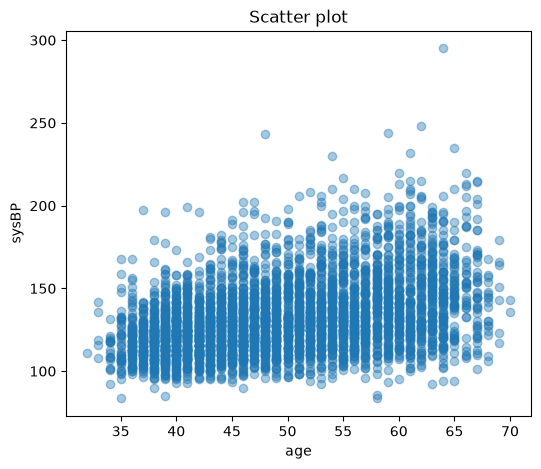

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.scatter(X, y, alpha=0.4)
plt.xlabel("age")  # Fill in with the feature name
plt.ylabel("sysBP")  # Fill in with the target name
plt.title("Scatter plot")
plt.show()


Now, let’s fit a simple **linear regression** and plot the fitted line on top of the scatter plot.  
The line shows the predicted values of **sysBP** for each age.  

**Exercise**: Fill in the missing code for fitting the model and predicting values.


In [17]:
%pip install -U scikit-learn
from sklearn.linear_model import LinearRegression
import numpy as np

model = LinearRegression()

# Fit the model to the data:
# the model learns the relationship between the input feature X and the target y
model.fit(X, y)

# Create prediction line
# Create two x-values spanning the range of the selected feature.
# These values can be used to plot the fitted regression line.
x_range = np.linspace(X[feature].min(), X[feature].max(), 2).reshape(-1, 1) #reshape changes the array from 1D ro 2D, which is required by sklearn
x_range


Note: you may need to restart the kernel to use updated packages.


array([[32.],
       [70.]])

In [18]:
# x_range = pd.DataFrame(x_range, columns=[feature])
y_pred_line = model.predict(x_range)   # Fill in with the right variable
print(y_pred_line)
print(y.min(), y.max())

[114.55016537 153.03487633]
83.5 295.0


/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


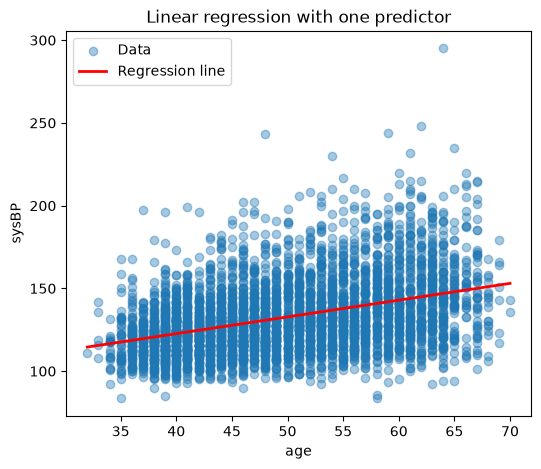

In [20]:
plt.figure(figsize=(6,5))
plt.scatter(X, y, alpha=0.4, label="Data")
plt.plot(x_range, y_pred_line, color="red", linewidth=2, label="Regression line")
plt.xlabel(feature)
plt.ylabel(target)
plt.title("Linear regression with one predictor")
plt.legend()
plt.show()


### Coefficient of Determination (R²)
Proportion of variance in the observed values explained by the model:  

$$
R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}
$$  

- Values close to **1** mean the model explains most of the variability.  
- Values close to **0** mean it does not perform better than the mean.  
- Can be **negative** if the model is worse than predicting the mean.

**Exercise**: Print the Coefficient of Determination (R²) using the `score()` method of the model.


In [22]:
r2 = model.score(X, y)
print(f"R^2 = {r2:.3f}")  # Fill in


R^2 = 0.155


### [Checkpoint S2]

**Q4:** In a simple linear regression with one predictor, what does the regression line represent?

-> The expected mean value of the response variable Y for any given value of the predictor X.

**Q5:** In scikit-learn, why do we need double brackets around `feature` when creating `X = df[[feature]]`?

-> because the library expects the feature matrix (X) to be a two-dimensional array-like object, not a one-dimensional object.

**Q6:** What does the scatter plot show?

-> Each point on the graph represents a single observation, with its horizontal (x) position determined by one variable and its vertical (y) position determined by the other.

**Q7:** What is the difference between `df[feature]` and `df[[feature]]`?

->df[feature] extracts the column as a 1D pandas Series (shape: (n,)), whereas df[[feature]] extracts it as a 2D pandas DataFrame with a single column (shape: (n, 1)), which is required by scikit-learn for the feature matrix X.

**Q8:** What does the R² statistic represent?

-> R²represents the proportion of the total variance in the dependent variable (Y) that is explained by the independent variable(s) (X) in the model.

**Q9:** What is the R² value obtained with your model? Report it to **3 decimal places**.

-> R²=0.155

## Pick another predictor (e.g. `totChol`, `BMI`, `heartRate` …)  

Now let’s test if another variable explains **Systolic Blood Pressure** better than `Age`.  

**Exercise**:  
1. Change the variable in `feature = "___"`.  
2. Re-run the regression steps.  
3. Compare the new \(R^2\) with the one you found for `Age`.  

Remember: a larger \(R^2\) means the predictor explains **sysBP** better.


### Handling missing values (NaNs)

Our new predictor may contain *missing values* (`NaN`).  
`sklearn.linear_model.LinearRegression` does **not** accept NaNs, so we must either:

1) **Drop** rows with missing values (simple, transparent), or  
2) **Impute** missing values (e.g., median) using a **Pipeline** (preferred for modeling).

We’ll try both approaches below.


In [23]:
# Usefull property to access the names of the columns of a panda dataframe
df.columns

Index(['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='str')

Dropped rows due to NaNs: 50 (kept 4190)


/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


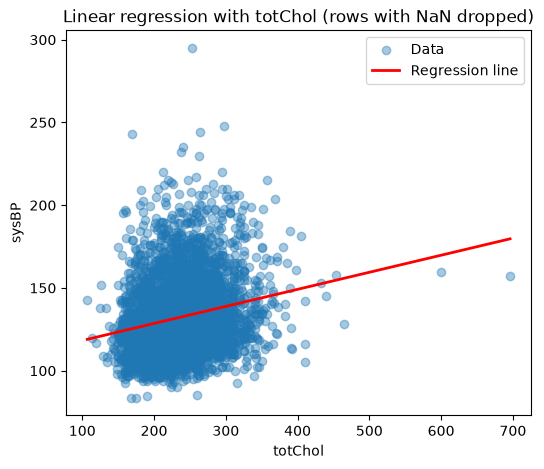

R² = 0.044


In [34]:

# Pick another predictor
target = "sysBP"
feature = "totChol"   # Fill with a predictor

# Keep only rows where both feature and target are present
df_clean = df[[feature, target]].dropna()
X = df_clean[[feature]]
y = df_clean[target]

print(f"Dropped rows due to NaNs: {len(df) - len(df_clean)} (kept {len(df_clean)})")

# Fit
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_range = np.linspace(X[feature].min(), X[feature].max(), 200).reshape(-1, 1)
y_pred_line = model.predict(x_range)

# Plot
plt.figure(figsize=(6,5))
plt.scatter(X[feature], y, alpha=0.4, label="Data")
plt.plot(x_range.ravel(), y_pred_line, color="red", linewidth=2, label="Regression line")
plt.xlabel(feature)
plt.ylabel(target)
plt.title(f"Linear regression with {feature} (rows with NaN dropped)")
plt.legend()
plt.show()

r2 = model.score(X, y)
print(f"R² = {r2:.3f}")  # Fill the blank


Dropped rows due to NaNs: 19 (kept 4221)


/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


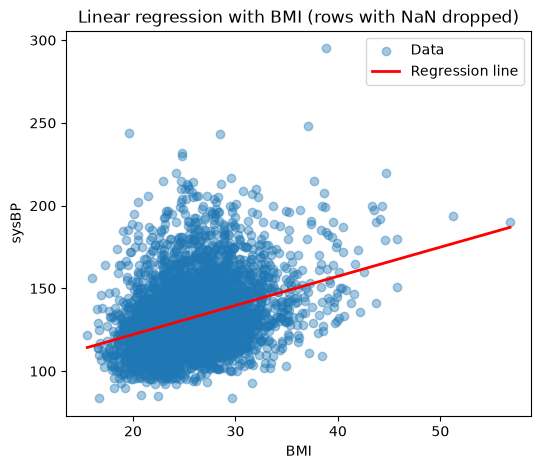

R² = 0.107


In [35]:

# Pick another predictor
target = "sysBP"
feature = "BMI"   # Fill with a predictor

# Keep only rows where both feature and target are present
df_clean = df[[feature, target]].dropna()
X = df_clean[[feature]]
y = df_clean[target]

print(f"Dropped rows due to NaNs: {len(df) - len(df_clean)} (kept {len(df_clean)})")

# Fit
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_range = np.linspace(X[feature].min(), X[feature].max(), 200).reshape(-1, 1)
y_pred_line = model.predict(x_range)

# Plot
plt.figure(figsize=(6,5))
plt.scatter(X[feature], y, alpha=0.4, label="Data")
plt.plot(x_range.ravel(), y_pred_line, color="red", linewidth=2, label="Regression line")
plt.xlabel(feature)
plt.ylabel(target)
plt.title(f"Linear regression with {feature} (rows with NaN dropped)")
plt.legend()
plt.show()

r2 = model.score(X, y)
print(f"R² = {r2:.3f}")  # Fill the blank


Dropped rows due to NaNs: 1 (kept 4239)


/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


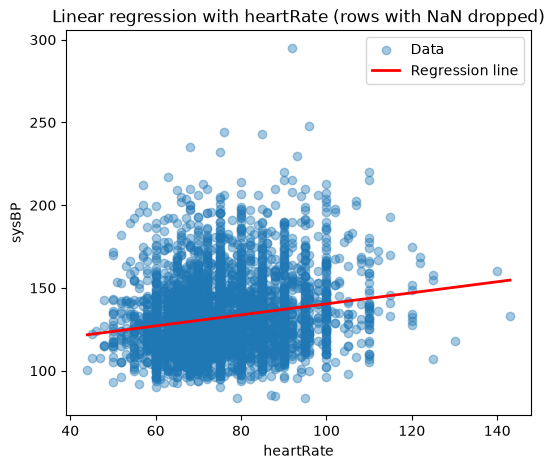

R² = 0.033


In [37]:

# Pick another predictor
target = "sysBP"
feature = "heartRate"   # Fill with a predictor

# Keep only rows where both feature and target are present
df_clean = df[[feature, target]].dropna()
X = df_clean[[feature]]
y = df_clean[target]

print(f"Dropped rows due to NaNs: {len(df) - len(df_clean)} (kept {len(df_clean)})")

# Fit
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_range = np.linspace(X[feature].min(), X[feature].max(), 200).reshape(-1, 1)
y_pred_line = model.predict(x_range)

# Plot
plt.figure(figsize=(6,5))
plt.scatter(X[feature], y, alpha=0.4, label="Data")
plt.plot(x_range.ravel(), y_pred_line, color="red", linewidth=2, label="Regression line")
plt.xlabel(feature)
plt.ylabel(target)
plt.title(f"Linear regression with {feature} (rows with NaN dropped)")
plt.legend()
plt.show()

r2 = model.score(X, y)
print(f"R² = {r2:.3f}")  # Fill the blank


Dropped rows due to NaNs: 388 (kept 3852)


/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


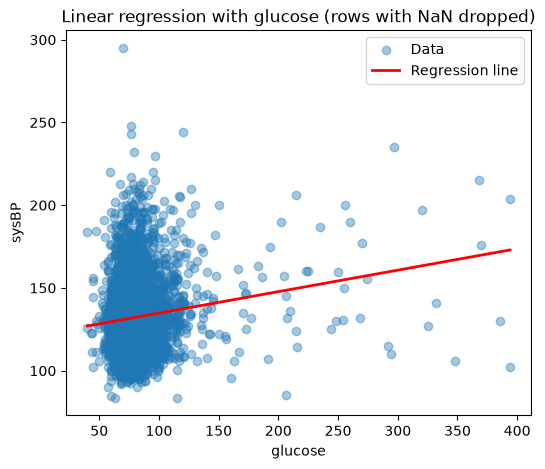

R² = 0.020


In [38]:

# Pick another predictor
target = "sysBP"
feature = "glucose"   # Fill with a predictor

# Keep only rows where both feature and target are present
df_clean = df[[feature, target]].dropna()
X = df_clean[[feature]]
y = df_clean[target]

print(f"Dropped rows due to NaNs: {len(df) - len(df_clean)} (kept {len(df_clean)})")

# Fit
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_range = np.linspace(X[feature].min(), X[feature].max(), 200).reshape(-1, 1)
y_pred_line = model.predict(x_range)

# Plot
plt.figure(figsize=(6,5))
plt.scatter(X[feature], y, alpha=0.4, label="Data")
plt.plot(x_range.ravel(), y_pred_line, color="red", linewidth=2, label="Regression line")
plt.xlabel(feature)
plt.ylabel(target)
plt.title(f"Linear regression with {feature} (rows with NaN dropped)")
plt.legend()
plt.show()

r2 = model.score(X, y)
print(f"R² = {r2:.3f}")  # Fill the blank


### [Checkpoint S3]  
**Q10:** Which predictor gives the best R² value ?

-> ages

**Q11:** How can we be sure it's the best predictor ?

-> Because it has the best R², but comparing to the ones tested at this point.

**Q12:** Do you see an other way to get an even higher R² value ?

-> Use multiple predictors (Multiple Linear Regression) or Non-linear models

We’ve been comparing single predictors one by one. Let’s **automate** this:

**Goal**
- Loop over a list of candidate predictors
- For each, fit a 1-variable LinearRegression (after dropping NaNs)
- Compute and store \(R^2\)
- Sort and report the best predictor

Fill the blanks `___` in the code cell below.


In [41]:
target = "sysBP"
candidate_features = ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

results = []  # (feature, r2, n_used)

for f in candidate_features:
    data = df[[f, target]].dropna()
    X = data[[f]]
    y = data[target]
    model = LinearRegression()
    model.fit(X, y)
    r2 = model.score(X, y)          # use the right method to get R²
    results.append((f, r2, len(data)))

# Sort by R² (descending)
results_sorted = sorted(results, key=lambda t: t[1], reverse=True)

# Print a tidy leaderboard (3 decimals)
for f, r2, n in results_sorted:
    print(f"{f:>10s}  R² = {r2:.3f}  (n={n})")   # Fill blank to print r2

best_f, best_r2, best_n = results_sorted[0]
print(f"\nBest single predictor by R²: {best_f} (R²={best_r2:.3f}, n={best_n})")
# Fill blank to print the feature giving the best r2, corresponding r2 and n


     diaBP  R² = 0.615  (n=4240)
prevalentHyp  R² = 0.485  (n=4240)
       age  R² = 0.155  (n=4240)
       BMI  R² = 0.107  (n=4221)
    BPMeds  R² = 0.065  (n=4187)
TenYearCHD  R² = 0.047  (n=4240)
   totChol  R² = 0.044  (n=4190)
 heartRate  R² = 0.033  (n=4239)
   glucose  R² = 0.020  (n=3852)
currentSmoker  R² = 0.017  (n=4240)
 education  R² = 0.017  (n=4135)
  diabetes  R² = 0.012  (n=4240)
cigsPerDay  R² = 0.008  (n=4211)
prevalentStroke  R² = 0.003  (n=4240)
      male  R² = 0.001  (n=4240)

Best single predictor by R²: diaBP (R²=0.615, n=4240)


### Step 5a — Two-predictor “hyperplane” (a plane in 3D)

With two predictors (e.g. `age` and `BMI`), linear regression fits a **plane**:

$$
\hat{y} = b_0 + b_1 \cdot \text{age} + b_2 \cdot \text{BMI}
$$

We will (1) plot the 3D scatter, (2) add the fitted plane, and (3) read off the equation and $R^2$.

/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


ŷ = 48.51 + 0.91·age + 1.50·BMI
R² = 0.230  (n=4221)


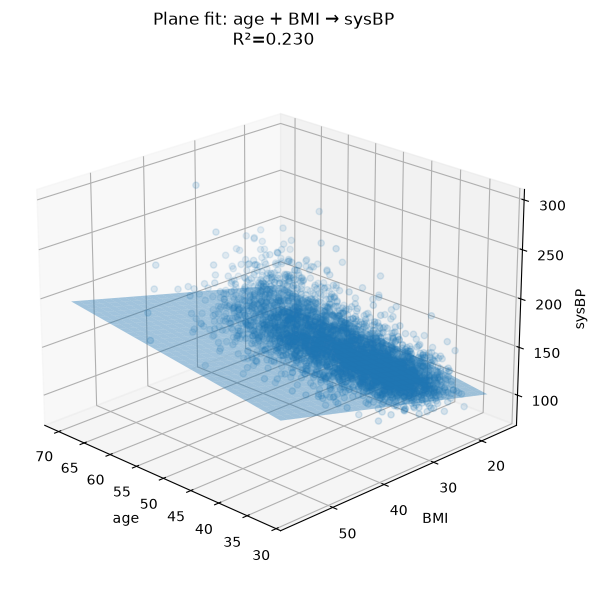

In [43]:
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D projection

# --- Choose variables ---
target = "sysBP"
features = ["age", "BMI"]  # change as you wish

data = df[features + [target]].dropna()
X = data[features]          # DataFrame (has column names)
y = data[target]            # Series

model = LinearRegression().fit(X, y)

# Grid as DataFrame with SAME column names & order
u = np.linspace(X[features[0]].min(), X[features[0]].max(), 30)
v = np.linspace(X[features[1]].min(), X[features[1]].max(), 30)
uu, vv = np.meshgrid(u, v)
grid_df = pd.DataFrame(np.c_[uu.ravel(), vv.ravel()], columns=features)

ww = model.predict(grid_df).reshape(uu.shape)   # <- names in, no warning

# --- Drop rows with any NaNs in the selected columns ---
data = df[features + [target]].dropna()
X = data[features]
y = data[target]

# --- Fit plane ---
model = LinearRegression().fit(X.to_numpy(), y.to_numpy()) # to_numpy()avoids warnings

b0 = model.intercept_
b1, b2 = model.coef_
r2 = model.score(X, y)
print(f"ŷ = {b0:.2f} + {b1:.2f}·{features[0]} + {b2:.2f}·{features[1]}")
print(f"R² = {r2:.3f}  (n={len(y)})")

# --- Create a grid and predict on the grid to draw the plane ---
x_lin = np.linspace(X[features[0]].min(), X[features[0]].max(), 30)
y_lin = np.linspace(X[features[1]].min(), X[features[1]].max(), 30)
xx, yy = np.meshgrid(x_lin, y_lin)
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict(grid).reshape(xx.shape)

# --- 3D plot: scatter + plane ---
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(X[features[0]], X[features[1]], y, alpha=0.45, s=20, label="Data")
ax.plot_surface(xx, yy, zz, alpha=0.4, linewidth=0, antialiased=True)

ax.set_xlabel(features[0]); ax.set_ylabel(features[1]); ax.set_zlabel(target)
ax.set_title(f"Plane fit: {features[0]} + {features[1]} → {target}\nR²={r2:.3f}")
ax.view_init(elev=22, azim=135)  # change angles to see the plane better
plt.tight_layout(); plt.show()


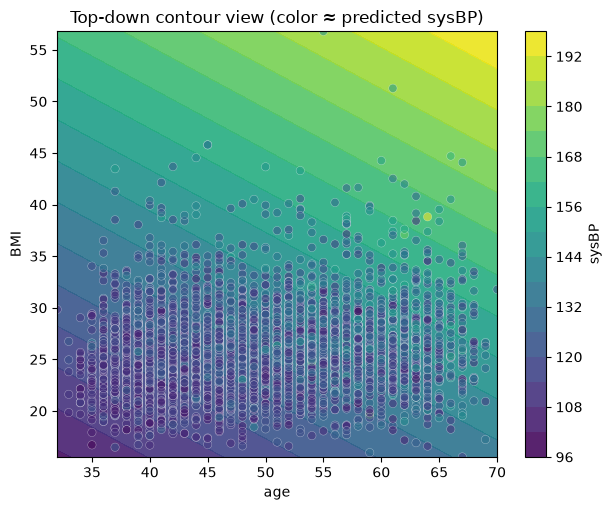

In [44]:
zz_pred = model.predict(np.c_[uu.ravel(), vv.ravel()]).reshape(uu.shape)
plt.figure(figsize=(6.3,5.2))
cs = plt.contourf(uu, vv, zz_pred, levels=18, alpha=0.9)
plt.scatter(X[features[0]], X[features[1]], c=y, alpha=0.55, edgecolor="white", linewidth=0.3)
plt.xlabel(features[0]); plt.ylabel(features[1])
plt.title("Top-down contour view (color ≈ predicted sysBP)")
plt.colorbar(cs, label=target)
plt.tight_layout(); plt.show()


**Exercise — What-if changes**

Using the fitted plane

$\hat{y} = b_0 + b_1 \cdot \text{age} + b_2 \cdot \text{BMI}$:

1. By how much does $\hat{y}$ change if **age increases by 10 years** (BMI fixed)?
2. By how much does $\hat{y}$ change if **BMI increases by 2 units** (age fixed)?
3. Combine both changes: **age +10 years and BMI +2 units** at the same time.
4. What would happen instead if **age increased by 10 years while BMI decreased by 2 units**?

Use the linearity of the model:

$\Delta \hat{y} = b_1,\Delta\text{age} + b_2,\Delta\text{BMI}$



In [47]:
# @title Exercise : compute Δŷ from b1, b2

from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

target = "sysBP"
features = ["age", "BMI"]

# Fit
data = df[features + [target]].dropna()
X, y = data[features], data[target]
model = LinearRegression().fit(X, y)
b0 = model.intercept_
b1, b2 = model.coef_

# === YOUR INPUTS (fill these) ===
d_age = 10
d_bmi = 2

# Guardrails so they must fill the values
if d_age is None or d_bmi is None:
    raise NotImplementedError("Fill d_age and d_bmi above.")

# === YOUR CALCULATIONS (fill these) ===
# Replace the None with expressions using b1, b2, d_age, d_bmi
delta_y_age  = d_age * b1
delta_y_bmi  = d_bmi * b2
delta_y_both = delta_y_age + delta_y_bmi

# Check they actually changed the Non£es
if any(v is None for v in (delta_y_age, delta_y_bmi, delta_y_both)):
    raise NotImplementedError("Compute delta_y_* using b1, b2, d_age, d_bmi.")

print(f"ŷ = {b0:.2f} + {b1:.2f}·{features[0]} + {b2:.2f}·{features[1]}")
print(f"Δŷ (age change only)  = {delta_y_age:+.2f}")
print(f"Δŷ (BMI change only)  = {delta_y_bmi:+.2f}")
print(f"Δŷ (both changes)     = {delta_y_both:+.2f}")


ŷ = 48.51 + 0.91·age + 1.50·BMI
Δŷ (age change only)  = +9.10
Δŷ (BMI change only)  = +3.00
Δŷ (both changes)     = +12.10


[Checkpoint S4]

**Q12**: By how much does $\hat{y}$ change if age increases by $10$ (BMI fixed)?  

-> +9.10

**Q13**: By how much does $\hat{y}$ change if BMI decreases by $2$ (age fixed)? 

-> +3

**Q14**: By how much does $\hat{y}$ change when both change (age $+10$ and BMI $-2$) at the same time?

-> +12.10


### Step 6 — Train/Test split (hold-out evaluation)

Goal: estimate how well our linear model generalizes to unseen data.

- Split the data into **train** (fit the model) and **test** (evaluate).
- Report **R²** on both sets (3 decimals).
- Use a simple **dropna**;
Key reminders:
- `X = df[features]` uses **double brackets** (2D).
- Keep a `random_state` for reproducibility.


Features: ['age', 'BMI', 'totChol']
Train R² = 0.240
 Test R² = 0.227
Test MAE = 14.06 mmHg
Test RMSE = 18.29 mmHg


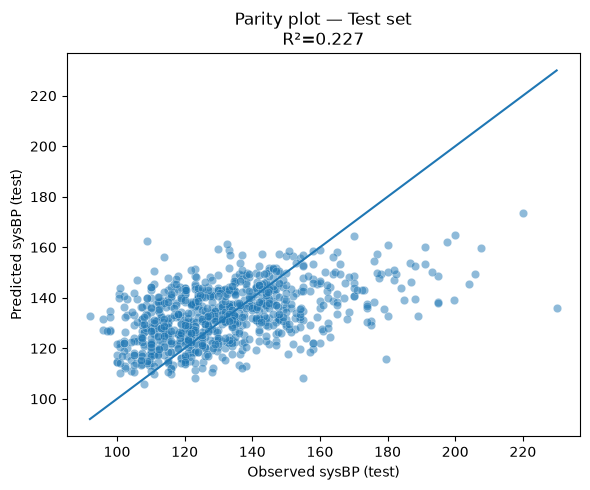

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

target = "sysBP"

features = ["age", "BMI", "totChol"]  # Add or remove predictors here.

data = df[features + [target]].dropna()
X = data[features]
y = data[target]




# Fix the random seed so the same rows go into the train and test sets
# each time this cell is run.
random_state = 43

test_size = 0.2 # 0.2 means 20% for testing and 80% for training.

# Stop with a clear error if either setting has not been provided.
if test_size is None or random_state is None:
    raise NotImplementedError("Set test_size")

#Fit and predict
# Split X and y together so each row of predictors stays paired with
# its corresponding target value. The default behavior shuffles the rows
# before splitting.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=random_state
)


# Fit the linear regression model using only the training observations.
model = LinearRegression().fit(X_train, y_train)

# Predict sysBP for the training observations.
# These predictions show how well the model fits the data it learned from.
y_pred_train = model.predict(X_train)

# Predict sysBP for the held-out test observations.
# These predictions estimate how well the model performs on unseen data.
y_pred_test = model.predict(X_test)

# Calculate R² on the training set.
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

# Calculate the test-set mean absolute error (MAE):
# the average absolute difference between observed and predicted sysBP,
# in the same units as sysBP (mmHg).
mae_test = mean_absolute_error(y_test, y_pred_test)

# Calculate the test-set root mean squared error (RMSE):
# the square root of the average squared prediction error, also in mmHg.
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

# Guard against accidentally leaving any metric uncomputed.
if any(v is None for v in (r2_train, r2_test, mae_test, rmse_test)):
    raise NotImplementedError(
        "Fill r2_train, r2_test, mae_test and rmse_test using sklearn.metrics."
    )

# Print which predictors were used by the model.
print(f"Features: {features}")

# Print training R² to three decimal places.
print(f"Train R² = {r2_train:.3f}")

# Print test R² to three decimal places.
print(f" Test R² = {r2_test:.3f}")

# Print test MAE to two decimal places, with its unit.
print(f"Test MAE = {mae_test:.2f} mmHg")

# Print test RMSE to two decimal places, with its unit.
print(f"Test RMSE = {rmse_test:.2f} mmHg")

# Find the overall lowest and highest values among the observed
# and predicted test values. These bounds will be used for the plot.
mn = float(min(y_test.min(), y_pred_test.min()))
mx = float(max(y_test.max(), y_pred_test.max()))

# Create a figure for the parity plot.
plt.figure(figsize=(6, 5))

# Plot observed test values on the x-axis and predicted values on the y-axis.
# Points closer to the diagonal represent more accurate predictions.
plt.scatter(
    y_test,
    y_pred_test,
    alpha=0.5,          # Make points partly transparent to reveal overlaps.
    edgecolor="white",  # Add a white outline around each point.
    linewidth=0.3       # Keep the outline thin.
)

# Draw the ideal-prediction diagonal: on this line, predicted = observed.
plt.plot([mn, mx], [mn, mx])

# Label the axes to distinguish observed values from predictions.
plt.xlabel("Observed sysBP (test)")
plt.ylabel("Predicted sysBP (test)")
plt.title(f"Parity plot — Test set\nR²={r2_test:.3f}")

# Adjust spacing so labels and title fit neatly.
plt.tight_layout()

# Display the plot.
plt.show()

Why do we keep a separate test set?
Which metric should you report to 3 decimals on the test set?
Which practice avoids data leakage during preprocessing?
What is your Test R² (3 decimals) with features you chose?
If Train R² ≫ Test R², what does this suggest and what could you try?

[Checkpoint S5]

**Q15**: Why do we keep a separate test set?

-> To evaluate how well the model generalizes to unseen data and to detect overfitting 

**Q16**: Which metric should you report to 3 decimals on the test set?

-> Fit preprocessing transformers (scalers, imputers, encoders) strictly on the training set only

**Q17**: Which practice avoids data leakage during preprocessing?

-> Fit transformers only on the training set (fit_transform on train) and strictly apply them to the tests.

**Q18**: What is your Test R² (3 decimals) with features you chose?

-> 0.227

**Q19**: If Train R² ≫ Test R², what does this suggest and what could you try?

-> It suggests that there is an overfitting: the model memorized the training noise and has high variance / poor generalizatio
To avoid that we can Apply feature selection to drop noisy predictors or collect more training data.